# H3 Initial Findings — Food Inflation and Food Insecurity by Gender

This notebook directly uses only pandas and matplotlib's pyplot. It explains data preparation and exploratory analysis before regression, one step at a time. In each chapter, read the question and processing rationale, run the code, and connect the output to the interpretation.

Extract the entire ZIP before opening the notebook. Keep the `data` folder beside the notebook. Select a Python kernel in Jupyter through Anaconda and run the cells from top to bottom. The openpyxl dependency used by pandas to read Excel must be installed.

Sources are the supplied Food Security CSV and OGHIST workbook, plus the downloaded [FAOSTAT Consumer Price Indices](https://www.fao.org/faostat/en/#data/CP). Country exclusion rules and the country-name mapping are reused from the team's H2 notebook. The original CPI CSV has only been renamed to `Food_CPI.csv`.

## 1. Translate the hypothesis into an analysis question

**Question**

What comparisons does H3 require?

**Reasoning and choices**

H3 asks whether periods of higher food inflation within the same country coincide with higher food insecurity, and whether this association is stronger for women.

The explanatory variable is food inflation. The outcomes are the prevalence of moderate or severe food insecurity among adult women and adult men. During preparation, one row represents a country-period, with separate columns for women and men. After calculating changes between adjacent periods, one row represents a country-transition.

The workflow is source inspection → food insecurity preparation → annual inflation calculation → three-year averages → income-group matching → missing-data checks → level comparisons → within-country change comparisons.

**What to check in the output**

Confirm that the three study periods do not overlap.

**Connection to the next step**

Read the three sources and inspect their structures.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

data_directory = "data/"
years_by_period = {
    "2014-2016": [2014, 2015, 2016],
    "2017-2019": [2017, 2018, 2019],
    "2020-2022": [2020, 2021, 2022]
}
period_order = list(years_by_period)
print(years_by_period)

{'2014-2016': [2014, 2015, 2016], '2017-2019': [2017, 2018, 2019], '2020-2022': [2020, 2021, 2022]}


## 2. Load the files and inspect their structures

**Question**

What information will we take from each file?

**Reasoning and choices**

The Food Security file has years spread across columns. The CPI file has rows for countries, years and months. OGHIST has income classifications in fiscal-year columns. Before joining them, we must put all three sources on a country-period basis.

Item codes contain F and M, so we read them as strings. The Excel table header is on the fifth row, which requires header=4. The marker `..` represents a missing income classification.

**What to check in the output**

Inspect row and column counts, column names and the first three rows. The number of rows in a full source file is not the research sample size.

**Connection to the next step**

Select the required gender-specific indicators and countries.

In [2]:
food_security = pd.read_csv(data_directory + "Food_Security_Data_E_All_Data.csv", dtype={"Item Code": str}, low_memory=False)
cpi_source = pd.read_csv(data_directory + "Food_CPI.csv", low_memory=False)
income_history = pd.read_excel(data_directory + "OGHIST_2026_10_08 (1).xlsx", sheet_name="Country Analytical History", header=4, na_values=[".."])

for name, table in [("Food security", food_security), ("CPI", cpi_source), ("Income", income_history)]:
    print("\n", name, table.shape)
    print(table.columns.tolist())
    print(table.head(3).to_string(index=False))


 Food security (18843, 158)
['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item', 'Element Code', 'Element', 'Unit', 'Y2000', 'Y2000F', 'Y2000N', 'Y20002002', 'Y20002002F', 'Y20002002N', 'Y2001', 'Y2001F', 'Y2001N', 'Y20012003', 'Y20012003F', 'Y20012003N', 'Y2002', 'Y2002F', 'Y2002N', 'Y20022004', 'Y20022004F', 'Y20022004N', 'Y2003', 'Y2003F', 'Y2003N', 'Y20032005', 'Y20032005F', 'Y20032005N', 'Y2004', 'Y2004F', 'Y2004N', 'Y20042006', 'Y20042006F', 'Y20042006N', 'Y2005', 'Y2005F', 'Y2005N', 'Y20052007', 'Y20052007F', 'Y20052007N', 'Y2006', 'Y2006F', 'Y2006N', 'Y20062008', 'Y20062008F', 'Y20062008N', 'Y2007', 'Y2007F', 'Y2007N', 'Y20072009', 'Y20072009F', 'Y20072009N', 'Y2008', 'Y2008F', 'Y2008N', 'Y20082010', 'Y20082010F', 'Y20082010N', 'Y2009', 'Y2009F', 'Y2009N', 'Y20092011', 'Y20092011F', 'Y20092011N', 'Y2010', 'Y2010F', 'Y2010N', 'Y20102012', 'Y20102012F', 'Y20102012N', 'Y2011', 'Y2011F', 'Y2011N', 'Y20112013', 'Y20112013F', 'Y20112013N', 'Y2012', 'Y2012F', 'Y2012N', 'Y201

## 3. Select the food insecurity indicators

**Question**

Are we comparing the same concept for women and men?

**Reasoning and choices**

Item 210091F measures moderate or severe food insecurity among adult women, and 210091M measures it among adult men. We select point estimates with Element equal to Value. Following H2, we exclude area codes of 1000 or more and the additional aggregate codes 351 and 420.

**What to check in the output**

Read Item, Element and Unit to confirm the definitions and units. There should be no duplicate rows for a country and gender indicator.

**Connection to the next step**

Stack the study-period columns into rows.

In [3]:
prevalence_source = food_security[
    food_security["Item Code"].isin(["210091F", "210091M"])
    & (food_security["Element"] == "Value")
    & (food_security["Area Code"] < 1000)
    & ~food_security["Area Code"].isin([351, 420])
].copy()
print(prevalence_source[["Item Code", "Item", "Element", "Unit"]].drop_duplicates().to_string(index=False))
print("Duplicate country-indicator rows", prevalence_source.duplicated(["Area Code", "Item Code"]).sum())
assert not prevalence_source.duplicated(["Area Code", "Item Code"]).any()

Item Code                                                                                                       Item Element Unit
  210091M   Prevalence of moderate or severe food insecurity in the male adult population (percent) (3-year average)   Value    %
  210091F Prevalence of moderate or severe food insecurity in the female adult population (percent) (3-year average)   Value    %
Duplicate country-indicator rows 0


## 4. Reshape period columns into rows

**Question**

How do we turn a column such as Y20142016 into a period variable?

**Reasoning and choices**

melt stacks the three period columns into a single value column while retaining the country and gender indicator. An explicit mapping connects source column names to study-period labels. Numeric conversion raises an error if a value cannot be interpreted as a number, so unexpected values can be investigated here.

**What to check in the output**

A country can have up to three periods multiplied by two genders. Check how many prevalence values are missing.

**Connection to the next step**

Put female and male estimates side by side for each country-period.

In [4]:
period_by_column = {}
for period, years in years_by_period.items():
    period_by_column["Y" + str(years[0]) + str(years[-1])] = period

prevalence_long = prevalence_source.melt(
    id_vars=["Area Code", "Area", "Item Code"],
    value_vars=list(period_by_column),
    var_name="source_period", value_name="prevalence"
)
prevalence_long["period"] = prevalence_long["source_period"].map(period_by_column)
prevalence_long["prevalence"] = pd.to_numeric(prevalence_long["prevalence"], errors="raise")
print(prevalence_long.head(8).to_string(index=False))
print("Missing prevalence values", prevalence_long["prevalence"].isna().sum())

 Area Code           Area Item Code source_period  prevalence    period
         2    Afghanistan   210091M     Y20142016        42.6 2014-2016
         2    Afghanistan   210091F     Y20142016        47.7 2014-2016
         3        Albania   210091M     Y20142016        35.2 2014-2016
         3        Albania   210091F     Y20142016        42.3 2014-2016
         4        Algeria   210091M     Y20142016        21.6 2014-2016
         4        Algeria   210091F     Y20142016        24.2 2014-2016
         5 American Samoa   210091M     Y20142016         NaN 2014-2016
         5 American Samoa   210091F     Y20142016         NaN 2014-2016
Missing prevalence values 486


## 5. Build a starting sample with both gender estimates

**Question**

What starting sample allows a comparable female–male comparison?

**Reasoning and choices**

pivot places female and male estimates in separate columns. Requiring both estimates ensures that the two gender means use the same countries in each period. dropna applies only to these two outcome columns.

**What to check in the output**

Check the starting sample count by period and confirm that prevalence falls between 0 and 100.

**Connection to the next step**

Prepare the food inflation measure to match this sample.

In [5]:
prevalence = prevalence_long.pivot(index=["Area Code", "Area", "period"], columns="Item Code", values="prevalence").reset_index()
prevalence.columns.name = None
prevalence = prevalence.rename(columns={"Area Code": "country_code", "Area": "country_name", "210091F": "female", "210091M": "male"})
starting_sample = prevalence.dropna(subset=["female", "male"]).copy()
assert starting_sample["female"].between(0, 100).all()
assert starting_sample["male"].between(0, 100).all()
print(starting_sample.groupby("period").size().to_string())
print("Total country-periods", len(starting_sample))
print(starting_sample.head(6).to_string(index=False))

period
2014-2016     99
2017-2019    121
2020-2022    146
Total country-periods 366
 country_code country_name    period  female  male
            1      Armenia 2017-2019    16.3  13.3
            1      Armenia 2020-2022     8.8   7.3
            2  Afghanistan 2014-2016    47.7  42.6
            2  Afghanistan 2017-2019    62.8  52.4
            2  Afghanistan 2020-2022    85.5  72.8
            3      Albania 2014-2016    42.3  35.2


## 6. Distinguish CPI from inflation

**Question**

Does a CPI of 120 mean inflation of 120%?

**Reasoning and choices**

Food CPI measures the price level relative to a reference year. H3 requires an annual rate of change in that price level. Here, annual food inflation is defined as the percentage change in annual-average Food CPI from the previous year.

FAOSTAT item 23013 contains Food CPI. Item 23014 contains monthly inflation observations. Averaging monthly year-on-year inflation rates and calculating the change in annual-average CPI are different calculations. We start with item 23013 so that each calculation is visible.

**What to check in the output**

Inspect the selected indicator and units, and check for duplicate country-year-month records.

**Connection to the next step**

Check monthly coverage before calculating annual-average CPI.

In [6]:
print(cpi_source[["Item Code", "Item"]].drop_duplicates().to_string(index=False))
cpi = cpi_source[
    (cpi_source["Item Code"] == 23013)
    & (cpi_source["Element"] == "Value")
    & cpi_source["Area Code"].isin(starting_sample["country_code"])
    & cpi_source["Year"].between(2013, 2022)
    & cpi_source["Months Code"].between(7001, 7012)
].copy()
cpi["Value"] = pd.to_numeric(cpi["Value"], errors="raise")
assert not cpi.duplicated(["Area Code", "Year", "Months Code"]).any()
print(cpi[["Item", "Unit", "Element"]].drop_duplicates().to_string(index=False))
print(cpi[["Area", "Year", "Months", "Value", "Flag"]].head(12).to_string(index=False))
print("Source flags")
print(cpi["Flag"].value_counts(dropna=False).to_string())

 Item Code                                                            Item
     23013                      Consumer Prices, Food Indices (2015 = 100)
     23012                   Consumer Prices, General Indices (2015 = 100)
     23014                                            Food price inflation
    230132              Consumer Prices, Food Indices (2015 = 100), median
    230131    Consumer Prices, Food Indices (2015 = 100), weighted average
    230122           Consumer Prices, General Indices (2015 = 100), median
    230121 Consumer Prices, General Indices (2015 = 100), weighted average
    230142                                    Food price inflation, median
    230141                          Food price inflation, weighted average
                                      Item Unit Element
Consumer Prices, Food Indices (2015 = 100)  NaN   Value
       Area  Year   Months   Value Flag
Afghanistan  2013  January  91.235    X
Afghanistan  2014  January  99.530    X
Afghanistan  2015 

## 7. Average only years with all 12 months

**Question**

Should a year with missing months be treated as a full-year average?

**Reasoning and choices**

groupby mean ignores missing values. Without a completeness rule, a 12-month average could be compared with an average based on only a few months. We count valid monthly values for each country-year and retain the annual CPI only when all 12 months are available. Since duplicate months were checked earlier, a count of 12 represents 12 distinct months.

**What to check in the output**

Inspect the number of incomplete country-years and the annual-average table. Completely absent country-years will remain missing in later joins.

**Connection to the next step**

Attach the previous annual average to calculate annual inflation.

In [7]:
annual_cpi = cpi.groupby(["Area Code", "Year"], as_index=False).agg(
    annual_cpi=("Value", "mean"), months=("Value", "count")
)
print("Incomplete country-years", (annual_cpi["months"] < 12).sum())
annual_cpi.loc[annual_cpi["months"] != 12, "annual_cpi"] = float("nan")
print(annual_cpi.head(12).to_string(index=False))

Incomplete country-years 2
 Area Code  Year  annual_cpi  months
         1  2013   95.477000      12
         1  2014   97.124000      12
         1  2015  100.116667      12
         1  2016   96.823000      12
         1  2017  100.774583      12
         1  2018  103.130583      12
         1  2019  105.063000      12
         1  2020  105.349500      12
         1  2021  117.162417      12
         1  2022  132.344500      12
         2  2013   93.618833      12
         2  2014  100.861833      12


## 8. Attach previous-year CPI and calculate annual inflation

**Question**

Why does calculating 2014 inflation require 2013 CPI?

**Reasoning and choices**

Annual inflation equals (current annual-average CPI / previous annual-average CPI − 1) × 100. For example, an increase from 100 to 110 gives 10% inflation.

We add one to Year in a copy of the previous-year table and join it to the current-year row. Joining on the year prevents a missing year from causing comparison with an observation two years earlier. The 2013 data supply the denominator for 2014 and do not enter the study periods themselves.

**What to check in the output**

Inspect current CPI, previous CPI and the calculated inflation rate on the same row.

**Connection to the next step**

Assign the annual inflation rates to their three-year study periods.

In [8]:
previous_cpi = annual_cpi[["Area Code", "Year", "annual_cpi"]].copy()
previous_cpi["Year"] = previous_cpi["Year"] + 1
previous_cpi = previous_cpi.rename(columns={"annual_cpi": "previous_cpi"})
annual_inflation = annual_cpi.merge(previous_cpi, on=["Area Code", "Year"], how="left", validate="one_to_one")
valid_previous = annual_inflation["previous_cpi"].dropna()
assert (valid_previous > 0).all()
annual_inflation["annual_inflation"] = (annual_inflation["annual_cpi"] / annual_inflation["previous_cpi"] - 1) * 100
print(annual_inflation.head(12).round(3).to_string(index=False))

 Area Code  Year  annual_cpi  months  previous_cpi  annual_inflation
         1  2013      95.477      12           NaN               NaN
         1  2014      97.124      12        95.477             1.725
         1  2015     100.117      12        97.124             3.081
         1  2016      96.823      12       100.117            -3.290
         1  2017     100.775      12        96.823             4.081
         1  2018     103.131      12       100.775             2.338
         1  2019     105.063      12       103.131             1.874
         1  2020     105.349      12       105.063             0.273
         1  2021     117.162      12       105.349            11.213
         1  2022     132.344      12       117.162            12.958
         2  2013      93.619      12           NaN               NaN
         2  2014     100.862      12        93.619             7.737


## 9. Calculate three-year average inflation

**Question**

How do we align inflation with three-year food insecurity estimates?

**Reasoning and choices**

The arithmetic mean of annual inflation in 2014, 2015 and 2016 is assigned to 2014–2016. Each year has equal weight, and all three annual rates must be available. This is different from cumulative price growth over three years, so tables and charts label it average annual inflation.

**What to check in the output**

Check that each retained period has three valid annual rates. Set the average to missing when fewer than three are available.

**Connection to the next step**

Prepare the income classifications for matching by country name.

In [9]:
period_by_year = {}
for period, years in years_by_period.items():
    for year in years:
        period_by_year[year] = period
annual_inflation["period"] = annual_inflation["Year"].map(period_by_year)
period_inflation = annual_inflation.groupby(["Area Code", "period"], as_index=False).agg(
    inflation=("annual_inflation", "mean"), years_available=("annual_inflation", "count")
)
period_inflation.loc[period_inflation["years_available"] != 3, "inflation"] = float("nan")
period_inflation = period_inflation.rename(columns={"Area Code": "country_code"})
print(period_inflation.groupby("period")["years_available"].value_counts().to_string())
print(period_inflation.head(9).round(3).to_string(index=False))

period     years_available
2014-2016  3                  148
2017-2019  3                  146
           0                    2
2020-2022  3                  146
           2                    1
 country_code    period  inflation  years_available
            1 2014-2016      0.505                3
            1 2017-2019      2.764                3
            1 2020-2022      8.148                3
            2 2014-2016      4.188                3
            2 2017-2019      3.204                3
            2 2020-2022     11.478                3
            3 2014-2016      3.246                3
            3 2017-2019      3.168                3
            3 2020-2022      6.425                3


## 10. Align income years and country names

**Question**

Why must fiscal years and country names be standardized?

**Reasoning and choices**

Following H2, we assign FY17, FY20 and FY23 to the three periods. These classifications use income information for 2015, 2018 and 2021, respectively, matching the middle year of each period. World Bank and FAOSTAT names sometimes differ, so we reuse H2's country-name mapping.

Income groups describe countries' economic backgrounds. Group comparisons in this notebook do not statistically control for other conditions.

**What to check in the output**

Check the mapping into four income groups. Failed country-name matches will be examined after joining.

**Connection to the next step**

Join the sources with left merges so that unmatched observations remain visible.

In [10]:
income_source = income_history.dropna(subset=[income_history.columns[0]]).rename(columns={income_history.columns[1]: "country_name"})[["country_name", "FY17", "FY20", "FY23"]].copy()
country_name_replacements = {
    "Bahamas, The": "Bahamas",
    "Bolivia": "Bolivia (Plurinational State of)",
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Iran, Islamic Rep.": "Iran (Islamic Republic of)",
    "Kyrgyz Republic": "Kyrgyzstan",
    "Lao PDR": "Lao People's Democratic Republic",
    "Naoero": "Nauru",
    "Netherlands": "Netherlands (Kingdom of the)",
    "West Bank and Gaza": "Palestine",
    "Korea, Rep.": "Republic of Korea",
    "Moldova": "Republic of Moldova",
    "St. Lucia": "Saint Lucia",
    "St. Vincent and the Grenadines": "Saint Vincent and the Grenadines",
    "São Tomé and Príncipe": "Sao Tome and Principe",
    "Slovak Republic": "Slovakia",
    "Tanzania": "United Republic of Tanzania",
    "United Kingdom": "United Kingdom of Great Britain and Northern Ireland",
    "United States": "United States of America",
    "Yemen, Rep.": "Yemen"
}

income_source["country_name"] = income_source["country_name"].str.strip().replace(country_name_replacements)
period_by_income_year = {"FY17": "2014-2016", "FY20": "2017-2019", "FY23": "2020-2022"}
income = income_source.melt(id_vars="country_name", value_vars=list(period_by_income_year), var_name="income_year", value_name="income_code")
income["period"] = income["income_year"].map(period_by_income_year)
income["income_group"] = income["income_code"].map({"L": "Low income", "LM": "Lower-middle income", "UM": "Upper-middle income", "H": "High income"})
print(income.head(8).to_string(index=False))

       country_name income_year income_code    period        income_group
        Afghanistan        FY17           L 2014-2016          Low income
            Albania        FY17          UM 2014-2016 Upper-middle income
            Algeria        FY17          UM 2014-2016 Upper-middle income
     American Samoa        FY17          UM 2014-2016 Upper-middle income
            Andorra        FY17           H 2014-2016         High income
             Angola        FY17          UM 2014-2016 Upper-middle income
Antigua and Barbuda        FY17           H 2014-2016         High income
          Argentina        FY17          UM 2014-2016 Upper-middle income


## 11. Record matching and sample losses

**Question**

How are the observations entering the analysis selected?

**Reasoning and choices**

Food insecurity and inflation are joined by country code and period. Income groups are joined by standardized country name and period. The validate argument detects duplicate keys that could unexpectedly multiply rows.

First count losses from missing inflation. Then count missing income groups among observations that have inflation. This sequence prevents counting an excluded row twice.

**What to check in the output**

For each period, verify that starting observations equal inflation losses plus additional income losses plus retained observations. Read the excluded-country list.

**Connection to the next step**

Add the female-minus-male gap to the completed table.

In [11]:
matched = starting_sample.merge(period_inflation, on=["country_code", "period"], how="left", validate="one_to_one")
matched = matched.merge(income[["country_name", "period", "income_group"]], on=["country_name", "period"], how="left", validate="many_to_one")
matched["missing_inflation"] = matched["inflation"].isna()
matched["missing_income_after_inflation"] = ~matched["missing_inflation"] & matched["income_group"].isna()
matched["retained"] = ~matched["missing_inflation"] & matched["income_group"].notna()
sample_flow = matched.groupby("period").agg(start=("country_code", "size"), missing_inflation=("missing_inflation", "sum"), missing_income=("missing_income_after_inflation", "sum"), retained=("retained", "sum"))
assert (sample_flow["start"] == sample_flow[["missing_inflation", "missing_income", "retained"]].sum(axis=1)).all()
print(sample_flow.to_string())
print("\nExcluded country-periods")
print(matched.loc[~matched["retained"], ["country_name", "period", "years_available", "missing_inflation", "missing_income_after_inflation"]].to_string(index=False))
analysis = matched.loc[matched["retained"], ["country_code", "country_name", "period", "income_group", "inflation", "female", "male"]].copy()

           start  missing_inflation  missing_income  retained
period                                                       
2014-2016     99                  0               0        99
2017-2019    121                  1               0       120
2020-2022    146                  5               0       141

Excluded country-periods
                    country_name    period  years_available  missing_inflation  missing_income_after_inflation
        Central African Republic 2020-2022              2.0               True                           False
                          Guyana 2020-2022              NaN               True                           False
                           Nauru 2020-2022              NaN               True                           False
                           Yemen 2017-2019              0.0               True                           False
                           Yemen 2020-2022              NaN               True                           Fals

## 12. Inspect the final sample and gender gap

**Question**

Does higher female prevalence imply a stronger association with inflation?

**Reasoning and choices**

We define gap as female minus male prevalence. A positive gap means higher female food insecurity, measured in percentage points. This difference in levels alone does not establish a stronger female association with inflation. Later, we examine inflation changes together with changes in the gender gap.

**What to check in the output**

Check the number of countries, country-periods, countries observed in all three periods, and the direction of the gap.

**Connection to the next step**

Summarize the overall data by period and income group.

In [12]:
analysis["gap"] = analysis["female"] - analysis["male"]
period_counts = analysis.groupby("country_code")["period"].nunique()
print("Country-periods", len(analysis))
print("Countries or economies", analysis["country_code"].nunique())
print("Observed in all three periods", (period_counts == 3).sum())
print("Female higher / equal / male higher", (analysis["gap"] > 0).sum(), (analysis["gap"] == 0).sum(), (analysis["gap"] < 0).sum())
print(analysis.head(8).round(2).to_string(index=False))

Country-periods 360
Countries or economies 147
Observed in all three periods 95
Female higher / equal / male higher 247 27 86
 country_code country_name    period        income_group  inflation  female  male  gap
            1      Armenia 2017-2019 Upper-middle income       2.76    16.3  13.3  3.0
            1      Armenia 2020-2022 Upper-middle income       8.15     8.8   7.3  1.5
            2  Afghanistan 2014-2016          Low income       4.19    47.7  42.6  5.1
            2  Afghanistan 2017-2019          Low income       3.20    62.8  52.4 10.4
            2  Afghanistan 2020-2022          Low income      11.48    85.5  72.8 12.7
            3      Albania 2014-2016 Upper-middle income       3.25    42.3  35.2  7.1
            3      Albania 2017-2019 Upper-middle income       3.17    40.7  33.6  7.1
            3      Albania 2020-2022 Upper-middle income       6.42    34.0  26.3  7.7


## 13. Inspect distributions and extreme values

**Question**

Does a single mean represent the sample well?

**Reasoning and choices**

Each country receives equal weight. A large difference between mean and median inflation may indicate that a few high values raise the mean. Inspect the largest values and their countries, without deleting observations simply because they are large. Period samples contain different countries, so changes in period means also reflect changes in sample composition.

**What to check in the output**

Read mean and median inflation alongside the ten highest observations.

**Connection to the next step**

Plot income-group averages while distinguishing these level comparisons from within-country changes.

In [13]:
period_summary = analysis.groupby("period").agg(countries=("country_code", "size"), inflation_mean=("inflation", "mean"), inflation_median=("inflation", "median"), inflation_max=("inflation", "max"), female_mean=("female", "mean"), male_mean=("male", "mean"), gap_mean=("gap", "mean"))
print(period_summary.round(2).to_string())
print("\nTen highest inflation observations")
print(analysis.nlargest(10, "inflation")[["country_name", "period", "inflation"]].round(2).to_string(index=False))

           countries  inflation_mean  inflation_median  inflation_max  female_mean  male_mean  gap_mean
period                                                                                                 
2014-2016         99            3.90              2.73          23.90        25.30      23.08      2.23
2017-2019        120            5.89              2.52         124.54        27.62      25.88      1.75
2020-2022        141           12.74              6.90         285.60        30.71      28.68      2.03

Ten highest inflation observations
              country_name    period  inflation
                  Zimbabwe 2020-2022     285.60
                   Lebanon 2020-2022     268.22
                  Zimbabwe 2017-2019     124.54
               South Sudan 2017-2019     117.90
                 Argentina 2020-2022      57.15
                  Suriname 2020-2022      52.06
Iran (Islamic Republic of) 2020-2022      49.85
                 Argentina 2017-2019      36.28
            

## 14. Plot female and male means by income group

**Question**

In which economic groups is food insecurity higher?

**Reasoning and choices**

Group country-period observations by period and income group, then calculate female and male means. Use the same vertical scale in each panel for consistent visual comparison. Include country counts in the table so that means based on small groups are interpreted cautiously.

**What to check in the output**

Read each group’s country count and gender means before examining the chart.

**Connection to the next step**

Prepare the within-country changes central to H3.

   period        income_group  countries  inflation_mean  female_mean  male_mean  gap_mean
2014-2016         High income         37            0.67         8.87       7.49      1.39
2014-2016          Low income         13            5.83        59.38      58.60      0.78
2014-2016 Lower-middle income         21            7.31        32.95      29.67      3.28
2014-2016 Upper-middle income         28            4.72        25.46      22.24      3.22
2017-2019         High income         37            1.90         8.08       7.00      1.08
2017-2019          Low income         18           10.74        58.37      57.86      0.51
2017-2019 Lower-middle income         28            9.04        36.48      34.67      1.81
2017-2019 Upper-middle income         37            5.14        25.52      22.55      2.97
2020-2022         High income         43            5.51         9.45       8.17      1.29
2020-2022          Low income         16           11.59        63.71      62.80      0.91

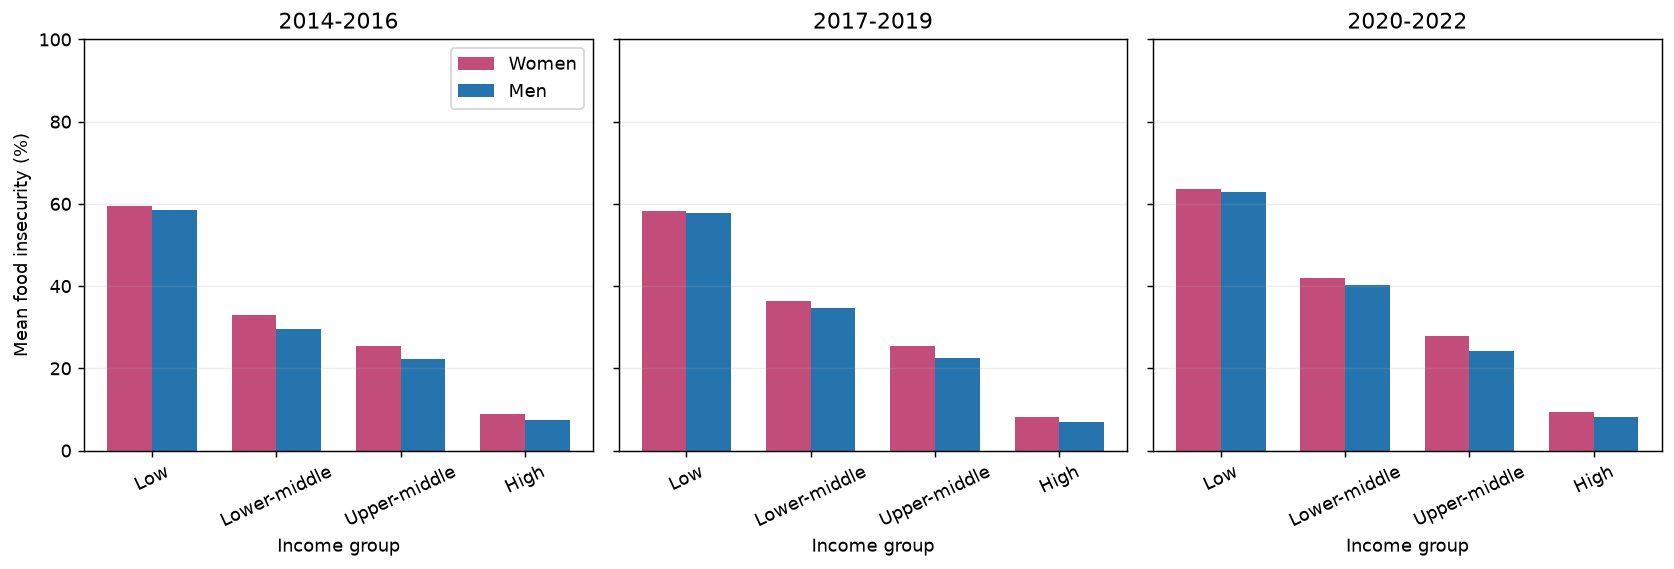

In [14]:
income_order = ["Low income", "Lower-middle income", "Upper-middle income", "High income"]
group_summary = analysis.groupby(["period", "income_group"], as_index=False).agg(countries=("country_code", "size"), inflation_mean=("inflation", "mean"), female_mean=("female", "mean"), male_mean=("male", "mean"), gap_mean=("gap", "mean"))
print(group_summary.round(2).to_string(index=False))
figure, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for axis, period in zip(axes, period_order):
    panel = group_summary[group_summary["period"] == period].set_index("income_group").reindex(income_order)
    positions = list(range(4))
    axis.bar([x - 0.18 for x in positions], panel["female_mean"], width=0.36, color="#c34d7a", label="Women")
    axis.bar([x + 0.18 for x in positions], panel["male_mean"], width=0.36, color="#2574ad", label="Men")
    axis.set_xticks(positions, ["Low", "Lower-middle", "Upper-middle", "High"], rotation=25)
    axis.set_title(period)
    axis.set_ylim(0, 100)
    axis.set_xlabel("Income group")
    axis.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Mean food insecurity (%)")
axes[0].legend()
figure.tight_layout()
plt.show()

## 15. Match adjacent periods within countries

**Question**

How can we examine change over time within the same country?

**Reasoning and choices**

Match 2014–2016 to 2017–2019, and 2017–2019 to 2020–2022, separately. An inner merge on country code keeps countries observed in both periods. A country missing the middle period is not assigned a first-to-last comparison spanning a longer interval.

Change is later minus earlier. delta_inflation measures the change in an inflation rate, so its unit is percentage points. A negative value can occur while inflation itself remains positive. For example, inflation declining from 10% to 5% gives delta_inflation of −5 percentage points.

**What to check in the output**

Check matched country counts by transition and inspect actual before-and-after values.

**Connection to the next step**

Plot inflation changes against food insecurity changes.

In [15]:
change_tables = []
for earlier, later in [("2014-2016", "2017-2019"), ("2017-2019", "2020-2022")]:
    before = analysis[analysis["period"] == earlier][["country_code", "country_name", "inflation", "female", "male", "gap"]]
    after = analysis[analysis["period"] == later][["country_code", "inflation", "female", "male", "gap"]]
    paired = before.merge(after, on="country_code", how="inner", suffixes=("_before", "_after"), validate="one_to_one")
    paired["transition"] = earlier + " to " + later
    for variable in ["inflation", "female", "male", "gap"]:
        paired["delta_" + variable] = paired[variable + "_after"] - paired[variable + "_before"]
    change_tables.append(paired)
changes = pd.concat(change_tables, ignore_index=True)
assert not changes.duplicated(["country_code", "transition"]).any()
print(changes.groupby("transition").size().to_string())
print("Distinct countries contributing changes", changes["country_code"].nunique())
print(changes[["country_name", "transition", "inflation_before", "inflation_after", "delta_inflation", "delta_female", "delta_male", "delta_gap"]].head(10).round(2).to_string(index=False))

transition
2014-2016 to 2017-2019     95
2017-2019 to 2020-2022    117
Distinct countries contributing changes 117
country_name             transition  inflation_before  inflation_after  delta_inflation  delta_female  delta_male  delta_gap
 Afghanistan 2014-2016 to 2017-2019              4.19             3.20            -0.98          15.1         9.8        5.3
     Albania 2014-2016 to 2017-2019              3.25             3.17            -0.08          -1.6        -1.6        0.0
     Algeria 2014-2016 to 2017-2019              4.00             2.61            -1.39          -5.1        -5.5        0.4
   Argentina 2014-2016 to 2017-2019             14.29            36.28            21.99          17.7        15.4        2.3
   Australia 2014-2016 to 2017-2019              1.40             1.34            -0.07           1.3         3.8       -2.5
     Austria 2014-2016 to 2017-2019              1.17             1.64             0.46          -2.5        -1.5       -1.0
  Banglade

## 16. Examine H3 with scatter plots of changes

**Question**

Did food insecurity rise in countries where inflation became higher?

**Reasoning and choices**

Each point is one country-transition. A point with positive values on both axes represents increases in both inflation and food insecurity. The last panel plots the change in the female-minus-male gap. Positive co-movement between inflation and the gap would be consistent with H3’s expected gender pattern.

Correlation summarizes linear co-movement between changes. A country can contribute to both transitions, and other conditions change at the same time. These correlations do not establish statistical significance or causality. Results are shown separately for each transition.

**What to check in the output**

Inspect the full distribution, extreme points, gender panels and gap panel together.

**Connection to the next step**

Compare average changes by inflation direction and explore income groups.

            transition  countries  women_r  men_r  gap_r
2014-2016 to 2017-2019         95    0.004 -0.020  0.045
2017-2019 to 2020-2022        117    0.335  0.272  0.206


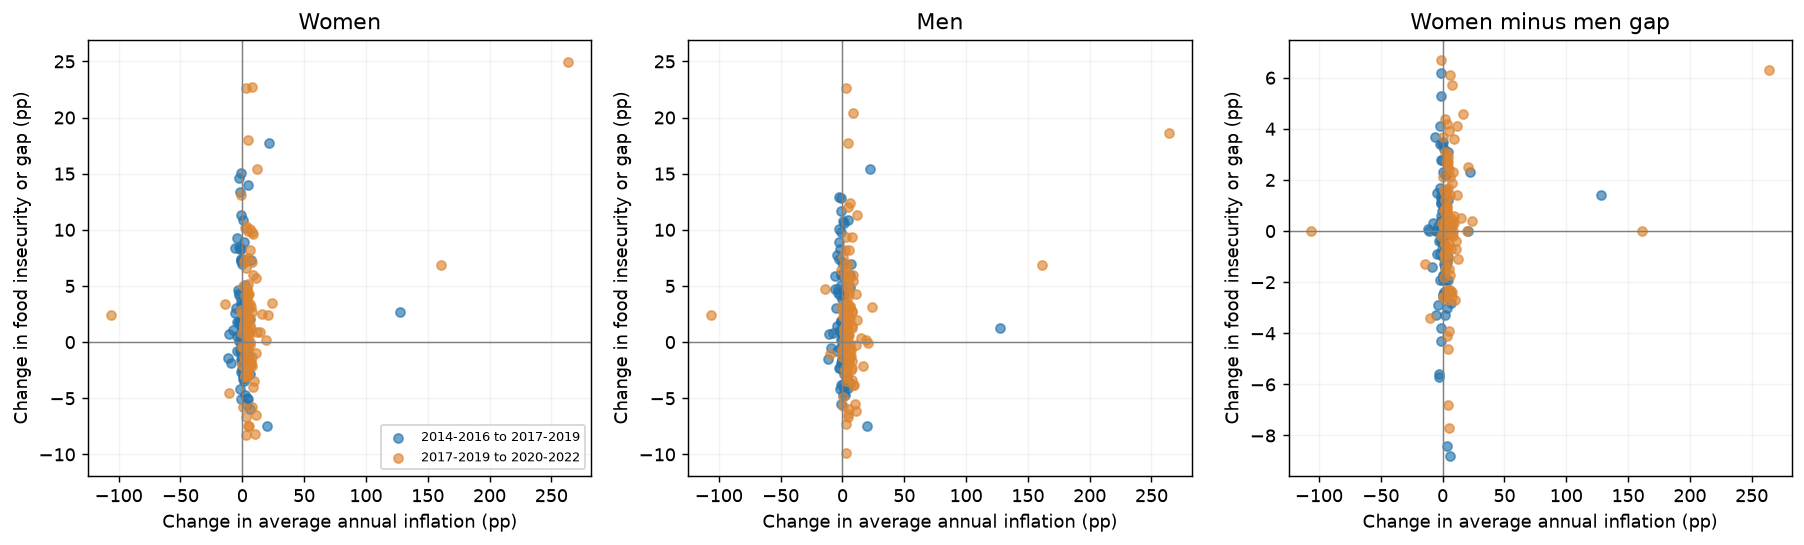

In [16]:
figure, axes = plt.subplots(1, 3, figsize=(14, 4.3))
transition_colors = ["#2574ad", "#dc8531"]
for axis, variable, title in zip(axes, ["delta_female", "delta_male", "delta_gap"], ["Women", "Men", "Women minus men gap"]):
    for (transition, group), color in zip(changes.groupby("transition"), transition_colors):
        axis.scatter(group["delta_inflation"], group[variable], label=transition, color=color, alpha=0.65, s=25)
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.axvline(0, color="gray", linewidth=0.8)
    axis.set_title(title)
    axis.set_xlabel("Change in average annual inflation (pp)")
    axis.set_ylabel("Change in food insecurity or gap (pp)")
    axis.grid(alpha=0.15)
axes[0].legend(fontsize=7)
gender_min = changes[["delta_female", "delta_male"]].min().min() - 2
gender_max = changes[["delta_female", "delta_male"]].max().max() + 2
axes[0].set_ylim(gender_min, gender_max)
axes[1].set_ylim(gender_min, gender_max)
figure.tight_layout()
plt.show()
correlation_rows = []
for transition, group in changes.groupby("transition"):
    correlation_rows.append({"transition": transition, "countries": len(group), "women_r": group["delta_inflation"].corr(group["delta_female"]), "men_r": group["delta_inflation"].corr(group["delta_male"]), "gap_r": group["delta_inflation"].corr(group["delta_gap"])})
change_correlations = pd.DataFrame(correlation_rows)
print(change_correlations.round(3).to_string(index=False))

## 17. Explore inflation direction and income groups

**Question**

Do average change patterns differ across groups?

**Reasoning and choices**

Classify positive inflation changes as Increased, negative changes as Decreased, and exactly zero changes as Unchanged. Compare average food insecurity changes across these categories within each transition. Membership in these groups is not randomly assigned.

For income-group comparisons over time, hold FY17 classification fixed to reduce movement of countries between groups. FY17 is the classification used for H2’s first period, rather than the classification in effect in 2014. These subgroup results are exploratory.

**What to check in the output**

Check country counts before comparing means, and interpret small groups cautiously.

**Connection to the next step**

Write initial findings using only the quantities established above.

In [17]:
changes["inflation_direction"] = "Unchanged"
changes.loc[changes["delta_inflation"] > 0, "inflation_direction"] = "Increased"
changes.loc[changes["delta_inflation"] < 0, "inflation_direction"] = "Decreased"
direction_summary = changes.groupby(["transition", "inflation_direction"]).agg(countries=("country_code", "size"), inflation_change=("delta_inflation", "mean"), female_change=("delta_female", "mean"), male_change=("delta_male", "mean"), gap_change=("delta_gap", "mean"))
print(direction_summary.round(2).to_string())
fixed_income = income[income["period"] == "2014-2016"][["country_name", "income_group"]].rename(columns={"income_group": "fixed_income_group"})
changes_with_income = changes.merge(fixed_income, on="country_name", how="left", validate="many_to_one")
print("\nMissing fixed income group", changes_with_income["fixed_income_group"].isna().sum())
income_change_summary = changes_with_income.groupby(["transition", "fixed_income_group"]).agg(countries=("country_code", "size"), inflation_change=("delta_inflation", "mean"), female_change=("delta_female", "mean"), male_change=("delta_male", "mean"), gap_change=("delta_gap", "mean"))
print(income_change_summary.round(2).to_string())

                                            countries  inflation_change  female_change  male_change  gap_change
transition             inflation_direction                                                                     
2014-2016 to 2017-2019 Decreased                   45             -2.68           3.08         2.88        0.20
                       Increased                   50              5.53           0.45         0.91       -0.46
2017-2019 to 2020-2022 Decreased                    7            -19.09           2.53         1.93        0.60
                       Increased                  110              9.01           2.16         1.86        0.30

Missing fixed income group 0
                                            countries  inflation_change  female_change  male_change  gap_change
transition             fixed_income_group                                                                      
2014-2016 to 2017-2019 High income                 36              1.09   

## 18. Initial Findings

The summary below is based on the actual sample and change statistics produced by the preceding cells. Read it in the order of sample, descriptive statistics, within-country changes, gender differences and limitations.

In [18]:
print("Country-periods", len(analysis))
print("Countries", analysis["country_code"].nunique())
print("Complete three-period countries", (period_counts == 3).sum())
print("Excluded country-periods", len(starting_sample) - len(analysis))
print("Country-transition observations", len(changes))
print("Countries with adjacent-period changes", changes["country_code"].nunique())
print(change_correlations.round(3).to_string(index=False))

Country-periods 360
Countries 147
Complete three-period countries 95
Excluded country-periods 6
Country-transition observations 212
Countries with adjacent-period changes 117
            transition  countries  women_r  men_r  gap_r
2014-2016 to 2017-2019         95    0.004 -0.020  0.045
2017-2019 to 2020-2022        117    0.335  0.272  0.206


### Initial interpretation based on the executed results

**Sample**

Of the 366 country-periods with both gender estimates, six are excluded because complete inflation data are unavailable. Income-group matching causes no additional losses. The final sample contains 360 country-periods from 147 countries or economies. Ninety-five countries appear in all three periods. Adjacent-period analysis uses 212 transition observations from 117 countries, with 95 countries in the first transition and 117 in the second.

**Inflation and food insecurity levels**

Mean food inflation across the three periods is 3.90%, 5.89% and 12.74%. The corresponding medians are 2.73%, 2.52% and 6.90%. The mean and median therefore move in opposite directions between the first two periods. The mean alone does not show that inflation increased in every country. Maximum inflation in the final period is 285.60%, indicating a strongly skewed distribution.

Mean female food insecurity is 25.30%, 27.63% and 30.71%, compared with 23.08%, 25.88% and 28.68% for men. Female prevalence is higher in all three periods. Because the sample composition differs by period, differences in these averages cannot be interpreted as changes in a fixed set of countries.

**Within-country changes and H3**

In the first transition, the correlation between inflation changes and food insecurity changes is 0.004 for women and −0.020 for men, both close to zero. In the second transition, the correlations are positive, at 0.335 for women and 0.272 for men. The pattern is therefore not consistent across the two transitions.

Correlations between inflation changes and changes in the female-minus-male gap are 0.045 and 0.206. The second transition shows an exploratory pattern consistent with H3’s expected stronger female association. However, differences between gender-specific correlations are not differences in effect sizes, and statistical significance has not been tested.

**Additional context from group comparisons**

In the second transition, the 110 countries with increased inflation have an average female food insecurity change of +2.16 percentage points. The seven countries with decreased inflation have an average change of +2.53 points. In the first transition, the increased-inflation group also has a smaller mean female change than the decreased-inflation group. Correlations use the magnitude of changes, whereas the direction-based comparison uses only their signs. These summaries provide different information and do not support a simple, consistent difference between the groups.

In the second transition, the mean gender gap increases in all four fixed income groups. In the first transition, it decreases in the high-income, low-income and lower-middle-income groups. These summaries do not establish that the inflation association differs by income group. Some initial patterns align with H3, but their sensitivity to period, sample composition and extreme observations requires further review.

## 19. Interpretation limits and next steps

This analysis establishes data structure and initial patterns. National averages do not directly measure individual exposure to food prices or resource allocation within households. Missing monthly and gender data affect sample selection, and extreme inflation observations can strongly affect means and correlations. Source flags indicate that some CPI observations are estimated or supplied by external organizations.

Adjacent-period comparisons reduce fixed differences in country levels, but do not control for income changes, conflict, policy or common period shocks. They cannot establish that H3 is proven or that the association is statistically stronger for women.

Further work within the course scope can inspect source observations for countries with large inflation changes and repeat the descriptive comparisons using only countries observed in all three periods. Before final submission, confirm whether the instructor expects annual inflation to be defined as the change in annual-average CPI.